# Laboratory Exercise 1: Volunteer Events

Volunteer Green is a platform that runs clean-up, planting, and restoration events for volunteers across Macedonia. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The events are synthetic and describe no real person, group, or organization.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [134]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [135]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [136]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:64226/'

## Task 1: Collect the Events

The platform lists its events across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every event into a table named `events`, with one row per event and these columns:

- `event_id`, the identifier of the event,
- `activity`, `kind`, and `city`,
- `area` and `unit`, the area of the site and the unit it is quoted in, exactly as the event states them,
- `volunteers`, the number of volunteers who took part,
- `difficulty`, `day`, `audience`, and `leaders`, the number of team leaders, and
- `by_partner`, which is true when a partner group organised the event and false when the platform organised it.

An event that does not state a field has a missing value in that column. Report how many events the platform lists and over how many pages they are spread.

In [137]:
# Write your solution here.

FIRST_PAGE_URL = "catalogue/page-1.html"
# html_page = requests.get(urljoin(BASE, FIRST_PAGE_URL))
# soup = BeautifulSoup(html_page.content, "html.parser")

AREA_UNIT_REGEX = re.compile(r"(\d[\d .]*) (m²|ha)")

def required_text(card: Tag, selector: str) -> str:
    element = card.select_one(selector)
    if element is None:
        raise ValueError(f"Listing {card['data-id']} has no {selector} element.")
    return element.get_text(strip=True)

def optional_text(card: Tag, selector: str) -> str | None:
    element = card.select_one(selector)
    return element.get_text(strip=True) if element else None

def captures(pattern: re.Pattern[str], text: str) -> tuple[str, ...]:
    match = pattern.search(text)
    if match is None:
        raise ValueError(f"{text!r} does not match {pattern.pattern!r}.")
    return match.groups()


def parse_event(card: Tag) -> dict[str, object]:
    area, unit = captures(AREA_UNIT_REGEX, required_text(card, "p.summary"))
    area = float(area.replace(" ", ""))

    volunteers = optional_text(card, "p.turnout.figure")
    if volunteers is None:
        volunteers = None
    else:
        volunteers = int(volunteers.split()[0])    

    leaders = optional_text(card, "li.leaders")
    if leaders is None:
        leaders = None
    else:
        leaders = int(leaders.split()[2])

    by_partner = required_text(card, "p.organiser.muted")

    return {
        "event_id": int(card["data-id"]),
        "activity": required_text(card, "h2.title"),
        "kind": required_text(card, "span.kind"),
        "city": required_text(card, "span.city"),
        "area": area,
        "unit": unit,
        "volunteers": volunteers,
        "difficulty": card.select_one("li.difficulty").text,
        "day": card.select_one("li.day").text,
        "audience": card.select_one("li.audience").text,
        "leaders": leaders,
        "by_partner": True if by_partner.split()[3] == "partner" else False
    }


records, url, pages = [], urljoin(BASE, FIRST_PAGE_URL), 0
while url:
    page = requests.get(url, timeout=10)
    page.raise_for_status()
    soup = BeautifulSoup(page.text, "lxml")

    #Za sekoja strana se sobiraat novi events
    records += [parse_event(card) for card in soup.select("article.card.event")]

    link = soup.select_one("a.next")

    url = urljoin(url, link["href"]) if link else None 
    pages += 1

events = pd.DataFrame(records)
print(events[0:10])

   event_id               activity         kind      city      area unit  \
0    762809            Flower beds     Planting    Skopje  12900.00   m²   
1    113111  Playground repainting  Restoration    Skopje      1.32   ha   
2    593942  Playground repainting  Restoration    Tetovo   8000.00   m²   
3    653599            Flower beds     Planting    Skopje      2.97   ha   
4    937467     Lakeshore clean-up     Clean-up    Tetovo      1.27   ha   
5    548375         Hedge planting     Planting    Skopje      0.55   ha   
6    280926          Tree planting     Planting    Skopje      0.76   ha   
7    999731  Playground repainting  Restoration  Kumanovo      1.32   ha   
8    335085         Hedge planting     Planting    Skopje      0.71   ha   
9    852390          Park clean-up     Clean-up    Skopje      2.46   ha   

   volunteers difficulty      day         audience  leaders  by_partner  
0        60.0   Moderate  Weekday      Adults only      4.0        True  
1        45.0  

## Task 2: Add the Surveys

The home page of the platform, `index.html` under `BASE`, points to a page of site surveys. Collect every survey the page holds, and add the pieces of litter, of plastic, and of cigarette butts counted for each event to `events`, so that every event appears exactly once. Name the result `df`.

Report how many surveys the page says it holds, how many you collected, and what you did about any survey that would put an event in `df` more than once.

In [138]:
# Write your solution here.
SURVEY_URL = "surveys.html"

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    tab = await browser.new_page()
    await tab.goto(urljoin(BASE, SURVEY_URL))
    await tab.wait_for_selector("#surveys td")
    rendered = await tab.content()
    await browser.close()

survey_page = BeautifulSoup(rendered, "lxml")
rows = survey_page.select("#surveys tr:has(td)")
surveys = pd.DataFrame(
    [
        {
            "event_id": int(row.select_one(".event-id").get_text()),
            "litter": int(row.select_one(".litter").get_text()),
            "plastic": int(row.select_one(".plastic").get_text()),
            "butts": int(row.select_one(".butts").get_text()),
        }
        for row in rows
    ]
)

# The page states its own count beside the table, as in "193 surveys".
stated = int(survey_page.select_one("#surveys-meta").get_text().split()[0])
print(f"The page says it holds {stated} surveys, and {len(surveys)} were collected.")

# try:
#     events.merge(surveys, on="event_id", validate="one_to_one")
# except pd.errors.MergeError as error:
#     print(error)

surveys[surveys.duplicated("event_id", keep=False)]

surveys = surveys.drop_duplicates()

#Ova prai merge na 2 DATAFRAMES
df = events.merge(
    surveys, on="event_id", how="left", validate="one_to_one", indicator=True
)
df["_merge"].value_counts()

df = df.drop(columns="_merge")
df.shape

print(df[0:10])

The page says it holds 193 surveys, and 193 were collected.
   event_id               activity         kind      city      area unit  \
0    762809            Flower beds     Planting    Skopje  12900.00   m²   
1    113111  Playground repainting  Restoration    Skopje      1.32   ha   
2    593942  Playground repainting  Restoration    Tetovo   8000.00   m²   
3    653599            Flower beds     Planting    Skopje      2.97   ha   
4    937467     Lakeshore clean-up     Clean-up    Tetovo      1.27   ha   
5    548375         Hedge planting     Planting    Skopje      0.55   ha   
6    280926          Tree planting     Planting    Skopje      0.76   ha   
7    999731  Playground repainting  Restoration  Kumanovo      1.32   ha   
8    335085         Hedge planting     Planting    Skopje      0.71   ha   
9    852390          Park clean-up     Clean-up    Skopje      2.46   ha   

   volunteers difficulty      day         audience  leaders  by_partner  \
0        60.0   Moderate  We

## Task 3: Describe the Events

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The difficulty levels have a natural order, from easy to demanding, and the type of `difficulty` keeps it.

In [153]:
# Write your solution here.

#Kategorii
for column in ["activity", "kind", "city", "unit", "day", "audience"]:
    df[column] = df[column].astype("category")

df["difficulty"] = pd.Categorical(
    df["difficulty"], categories=["Easy", "Moderate", "Demanding"], ordered=True
)

#Int64 dava da da ostane missing value kako <NA>
df = df.astype({"volunteers": "Int64", "leaders": "Int64"})
df.dtypes

event_id         int64
activity      category
kind          category
city          category
area           float64
unit          category
volunteers       Int64
difficulty    category
day           category
audience      category
leaders          Int64
by_partner        bool
litter           int64
plastic          int64
butts            int64
area_ha        float64
dtype: object

### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

volunteers    47
leaders       22
dtype: int64


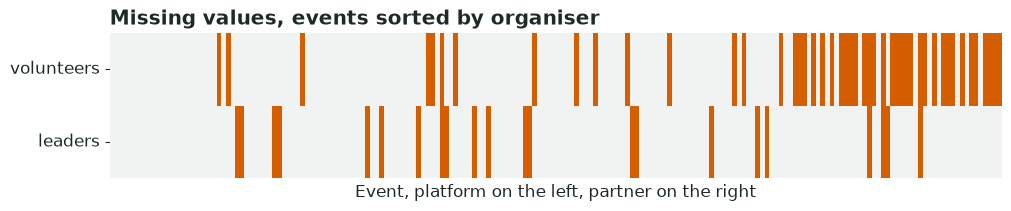

volunteers       leaders      
                  sum  mean     sum  mean
by_partner                               
False              14  0.10      18  0.12
True               33  0.69       4  0.08

In [168]:
# Write your solution here.

#Pokazuva kolku vrednosti falat vo sekoja od kolonite
print(df.isna().sum()[lambda counts: counts > 0])

fig, ax = plt.subplots(figsize=(10, 2))
missing_map = df.sort_values("by_partner")[["volunteers", "leaders"]].isna().T
sns.heatmap(missing_map, cbar=False, cmap=["#f1f3f2", PALETTE[1]], xticklabels=False, ax=ax)
ax.set(title="Missing values, events sorted by organiser", xlabel="Event, platform on the left, partner on the right")
ax.tick_params(axis="y", rotation=0)
plt.show()

df[["volunteers", "leaders"]].isna().groupby(df["by_partner"]).agg(["sum", "mean"]).round(2)

### 3.3 Areas in Two Units

Some events quote the area of the site in hectares and others in square metres. Compare the quoted areas within each unit, then add a column `area_ha` that states every area in hectares.

In [180]:
# Write your solution here.

print(df.groupby("unit", observed=True)["area"].agg(["median"]))

# 1 ha = 10000 m2.
df["area_ha"] = df["area"].where(df["unit"] == "ha", df["area"] / 10_000)

df.groupby("unit", observed=True)["area_ha"].agg(["count", "min", "median", "max"]).round(2)

        median
unit          
ha        1.16
m²    13200.00


,count,min,median,max
unit,,,,
ha,165,0.42,1.16,4.07
m²,27,0.58,1.32,2.67


### 3.4 The Turnout

Describe the number of volunteers by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical event better.

mean       62.52
median     59.00
range     143.00
std        25.31
IQR        30.00
skew        1.36
dtype: float64


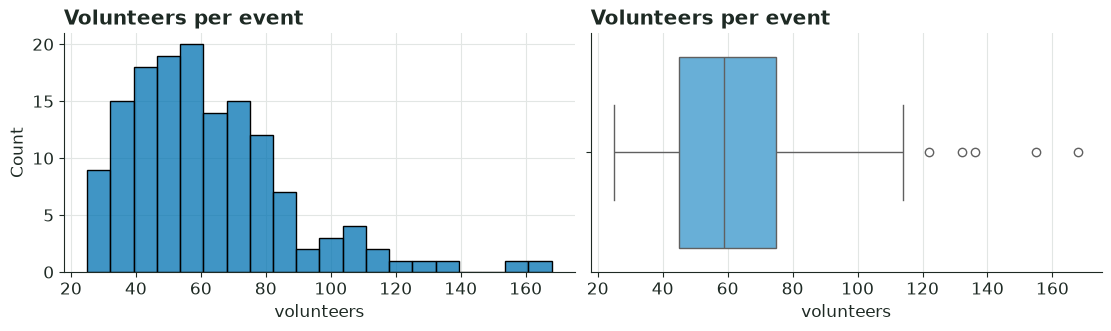

In [ ]:
# Write your solution here.
volunteers = df["volunteers"]
q1, q3 = volunteers.quantile([0.25, 0.75])
print(pd.Series({"mean": volunteers.mean(), "median": volunteers.median(), "range": volunteers.max() - volunteers.min(),
                 "std": volunteers.std(), "IQR": q3 - q1, "skew": volunteers.skew()}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sns.histplot(df, x="volunteers", bins=20, ax=axes[0])
sns.boxplot(df, x="volunteers", ax=axes[1], color=PALETTE[5])
axes[0].set_title("Volunteers per event")
axes[1].set_title("Volunteers per event")
plt.show()

# Skew e 1.36 shto znaci long right tail

### 3.5 Turnout by Difficulty

Compare the number of volunteers across the difficulty levels.

            count  mean  median   std
difficulty                           
Easy           45  47.2    44.0  18.7
Moderate       65  60.9    59.0  19.9
Demanding      35  85.3    81.0  25.7


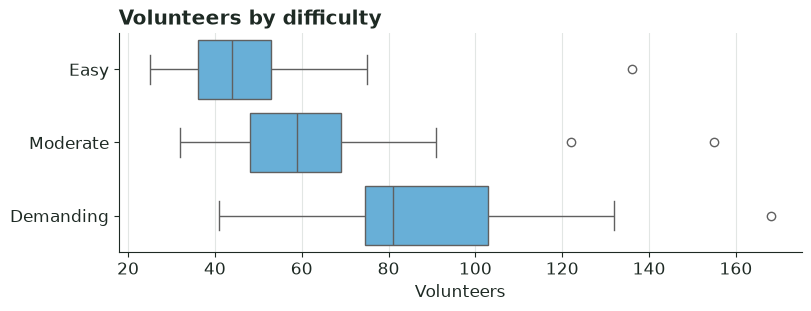

In [ ]:
# Write your solution here.

print(df.groupby("difficulty", observed=True)["volunteers"].agg(["count", "mean", "median", "std"]).round(1))

fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(df, x="volunteers", y="difficulty", color=PALETTE[5], ax=ax)
ax.set(title="Volunteers by difficulty", xlabel="Volunteers", ylabel="")
plt.show()
# shto po difficult e, povekje volunteers ima

### 3.6 Events by City

Show how the events are spread across the cities, and give the share of events in each city.

          count  share
city                  
Skopje       95  0.495
Tetovo       24  0.125
Bitola       23  0.120
Ohrid        22  0.115
Prilep       15  0.078
Kumanovo     13  0.068


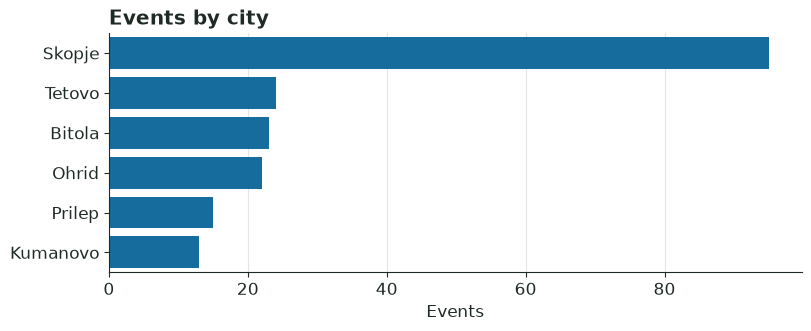

In [ ]:
# Write your solution here.

counts = df["city"].value_counts()
print(pd.DataFrame({"count": counts, "share": (counts / counts.sum()).round(3)}))

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.countplot(df, y="city", order=counts.index, ax=ax, color=PALETTE[0])
ax.set(title="Events by city", xlabel="Events", ylabel="")
plt.show()

### 3.7 Litter and Plastic

Show how the pieces of litter and the pieces of plastic counted on a plot move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

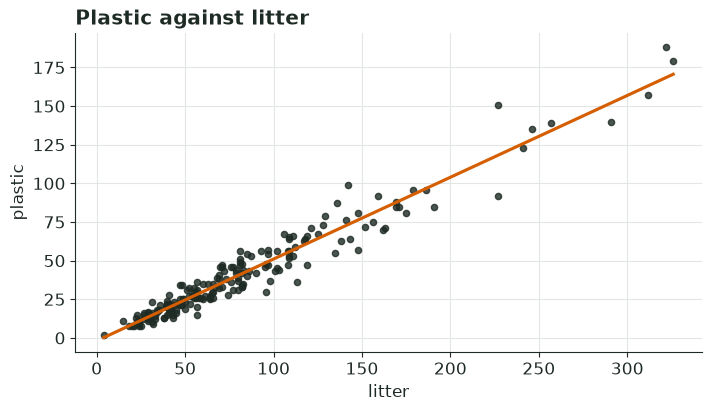

(np.float64(0.9714399026366968), np.float64(0.9609046002156038))

In [182]:
# Write your solution here.
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(df, x="litter", y="plastic", ci=None, ax=ax,
            scatter_kws={"color": INK, "s": 20}, line_kws={"color": PALETTE[1]})
ax.set_title("Plastic against litter")
plt.show()

# Pearson (0.97) i Spearman (0.96) se dvata blisku do 1 i skoro ednakvi,
# pa plastikata raste so otpadot blisku do prava linija.
df["litter"].corr(df["plastic"]), df["litter"].corr(df["plastic"], method="spearman")

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

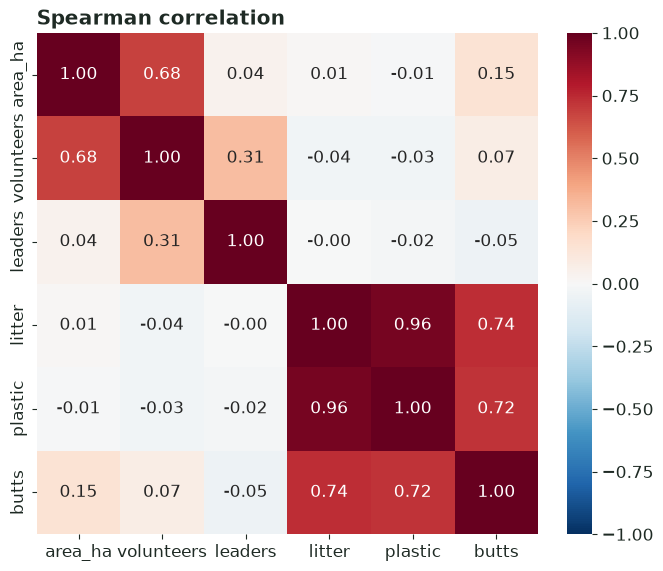

(('litter', 'plastic'), np.float64(0.96))

In [146]:
# Write your solution here.
# event_id e identifikator, a area mesha dve edinici, pa namesto nea se koristi area_ha.
numeric = ["area_ha", "volunteers", "leaders", "litter", "plastic", "butts"]
corr = df[numeric].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation")
plt.show()

# Dijagonalata ja sporeduva sekoja kolona so samata sebe, pa se izostava pred da se imenuva najsilniot par.
# litter i plastic se dvizhat zaedno najsilno.
pairs = corr[corr < 1].stack()
pairs.idxmax(), round(pairs.max(), 2)

### 3.9 Turnout by City and Difficulty

Find the combination of city and difficulty with the highest median number of volunteers, counting only the combinations with at least three events that state a turnout.

In [147]:
# Write your solution here.
# count gi preskoknuva vrednostite shto nedostasuvaat, pa gi broi samo nastanite so naveden broj na volonteri.
cells = df.groupby(["city", "difficulty"], observed=True)["volunteers"].agg(["count", "median"])
# Teshkite nastani vo Ohrid imaat najvisoka medijana na volonteri, 103, od tri nastani.
cells[cells["count"] >= 3].sort_values("median", ascending=False).head()

,,count,median
city,difficulty,,
Ohrid,Demanding,3,103.0
Tetovo,Demanding,6,90.5
Prilep,Demanding,3,79.0
Kumanovo,Demanding,4,77.5
Skopje,Demanding,17,77.0


## Task 4: Turnout

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the events that state a turnout.

### 4.1 The Advertised Turnout

The home page states an average number of volunteers per event. Decide whether the average turnout of the events differs from that statement, and give a range for the average turnout.

In [148]:
# Write your solution here.
# Pochetnata stranica go naveduva reklamiraniot prosek, kako vo "58 volunteers on average".
home = requests.get(urljoin(BASE, "index.html"), timeout=10).text
ADVERTISED = int(re.search(r"(\d+) volunteers on average", home).group(1))

# H0: prosechniot broj na volonteri e ednakov na reklamiraniot prosek.
turnout = df[df["volunteers"].notna()]
result = stats.ttest_1samp(turnout["volunteers"], popmean=ADVERTISED)
# p = 0.033 < 0.05, pa H0 se otfrla: prosechniot broj na volonteri od 62.5 se razlikuva od reklamiranite 58,
# a 95 % intervalot na doverba za prosekot e od 58.4 do 66.7 volonteri.
ADVERTISED, result, result.confidence_interval(0.95)

(58,
 TtestResult(statistic=np.float64(2.149301019665473), pvalue=np.float64(0.033281744887218356), df=np.int64(144)),
 ConfidenceInterval(low=np.float64(58.3630225914404), high=np.float64(66.67146016718029)))

### 4.2 Weekend and Weekday

Decide whether the events held at the weekend and on a weekday differ in their average turnout, and give a range for the difference, taken as weekend minus weekday.

In [149]:
# Write your solution here.
volunteers, day = turnout["volunteers"], turnout["day"]
weekend, weekday = volunteers[day == "Weekend"], volunteers[day == "Weekday"]
# H0: prosechniot broj na volonteri e ist za vikend i vo raboten den. Welch-oviot test dozvoluva razlichni varijansi.
welch = stats.ttest_ind(weekend, weekday, equal_var=False)
# p = 0.021 < 0.05, pa H0 se otfrla: nastanite za vikend privlekuvaat povekje volonteri, a 95 % intervalot
# na razlikata, vikend minus raboten den, e od 1.5 do 18.6 volonteri.
welch, welch.confidence_interval(0.95)

(TtestResult(statistic=np.float64(2.340861566762718), pvalue=np.float64(0.02110015812638434), df=np.float64(106.57007718895842)),
 ConfidenceInterval(low=np.float64(1.5449511284965034), high=np.float64(18.637250635983737)))

## Task 5: Difficulty and Audience

The questions of this task concern all events.

### 5.1 Audience by Difficulty

Decide whether the audience of an event depends on its difficulty, and give a range for the share of family-friendly events at each difficulty, using a percentile bootstrap.

In [150]:
# Write your solution here.
# H0: publikata na nastanot ne zavisi od negovata tezhina.
table = pd.crosstab(df["difficulty"], df["audience"])
result = stats.chi2_contingency(table)
print(table, result.pvalue, result.expected_freq.round(1), sep="\n")

family = df["audience"] == "Family-friendly"
shares = {}
for level in df["difficulty"].cat.categories:
    sample = family[df["difficulty"] == level].to_numpy()
    ci = stats.bootstrap((sample,), np.mean, n_resamples=9999, method="percentile", rng=rng).confidence_interval
    shares[level] = {"share": sample.mean(), "low": ci.low, "high": ci.high}
# p = 0.003 < 0.05 i site ochekuvani frekvencii se najmalku 5, pa H0 se otfrla: publikata zavisi
# od tezhinata. Udelot na nastani pogodni za semejstva opagja od 46 % (lesni) na 31 % (umereni)
# i 13 % (teshki).
pd.DataFrame(shares).T.round(3)

audience    Adults only  Family-friendly
difficulty                              
Easy                 36               30
Moderate             61               27
Demanding            33                5
0.002883784290863389
[[44.7 21.3]
 [59.6 28.4]
 [25.7 12.3]]


,share,low,high
Easy,0.455,0.333,0.576
Moderate,0.307,0.216,0.409
Demanding,0.132,0.026,0.237


### 5.2 The Mix of Difficulty Levels

The home page states how the events divide among the difficulty levels. Decide whether the events match that statement, and give a range for the share of demanding events, using a percentile bootstrap.

In [ ]:
# Write your solution here.
# Pochetnata stranica ja naveduva raspredelbata, kako vo "45 % easy, 35 % moderate, and 20 % demanding".
claimed = pd.Series({level.capitalize(): int(percent) / 100 for percent, level in re.findall(r"(\d+) % (\w+)", home)})
observed = df["difficulty"].value_counts()[claimed.index]
print(pd.DataFrame({"observed": observed.to_numpy() / observed.sum(), "claimed": claimed}).round(3))

# H0: nastanite se raspredeleni po tezhina onaka kako shto naveduva pochetnata stranica.
print(stats.chisquare(observed, f_exp=claimed * observed.sum()))
demanding = (df["difficulty"] == "Demanding").to_numpy()
# p = 0.004 < 0.05, pa H0 se otfrla: nastanite ne odgovaraat na navedenata raspredelba. Udelot na teshki
# nastani (19.8 %, interval od okolu 14 % do 26 %) se sovpagja so navedenite 20 %; razlikata e kaj
# lesnite nastani (34 % nasproti 45 %) i umerenite (46 % nasproti 35 %).
stats.bootstrap((demanding,), np.mean, n_resamples=9999, method="percentile", rng=rng).confidence_interval

           observed  claimed
Easy          0.344     0.45
Moderate      0.458     0.35
Demanding     0.198     0.20
Power_divergenceResult(statistic=np.float64(11.258928571428582), pvalue=np.float64(0.003590498293434358))


ConfidenceInterval(low=np.float64(0.140625), high=np.float64(0.2552083333333333))

: 

In [152]:
server.shutdown()